# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:Kaggle DigiDB dataset
https://www.kaggle.com/datasets/rtatman/digidb/data


**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:One categorical feature: Stage, Type, or Attribute


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: By watching the class video and by using a new data set


## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import kagglehub

path = kagglehub.dataset_download("rtatman/digidb")

print("Path to dataset files:", path)

100%|██████████| 14.3k/14.3k [00:00<00:00, 14.1MB/s]

Extracting files...
Path to dataset files: C:\Users\james\.cache\kagglehub\datasets\rtatman\digidb\versions\1


In [5]:
import os

for file in os.listdir(path):
    print(file)
    

DigiDB_digimonlist.csv
DigiDB_movelist.csv
DigiDB_supportlist.csv


In [6]:
import pandas as pd

digimon_df = pd.read_csv(
    os.path.join(path, "DigiDB_digimonlist.csv")
)

digimon_df.head()

,Number,Digimon,Stage,Type,Attribute,Memory,Equip Slots,Lv 50 HP,Lv50 SP,Lv50 Atk,Lv50 Def,Lv50 Int,Lv50 Spd
0,1,Kuramon,Baby,Free,Neutral,2,0,590,77,79,69,68,95
1,2,Pabumon,Baby,Free,Neutral,2,0,950,62,76,76,69,68
2,3,Punimon,Baby,Free,Neutral,2,0,870,50,97,87,50,75
3,4,Botamon,Baby,Free,Neutral,2,0,690,68,77,95,76,61
4,5,Poyomon,Baby,Free,Neutral,2,0,540,98,54,59,95,86


In [7]:
import pandas as pd

digimon_df = pd.read_csv(
    os.path.join(path, "DigiDB_digimonlist.csv")
)

digimon_df.tail()

,Number,Digimon,Stage,Type,Attribute,Memory,Equip Slots,Lv 50 HP,Lv50 SP,Lv50 Atk,Lv50 Def,Lv50 Int,Lv50 Spd
244,245,Valkyrimon,Mega,Free,Wind,18,3,1330,139,148,129,129,168
245,246,ShineGreymon BM,Mega,Vaccine,Fire,22,2,1980,114,228,104,84,168
246,247,MirageGaogamon BM,Mega,Data,Light,20,2,1440,124,178,104,158,174
247,248,Ravemon BM,Mega,Vaccine,Wind,20,2,1040,133,149,139,144,213
248,249,Rosemon BM,Mega,Data,Plant,20,2,1480,143,149,139,159,143


In [8]:
digimon_df.shape

(249, 13)

In [9]:
digimon_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Number       249 non-null    int64 
 1   Digimon      249 non-null    object
 2   Stage        249 non-null    object
 3   Type         249 non-null    object
 4   Attribute    249 non-null    object
 5   Memory       249 non-null    int64 
 6   Equip Slots  249 non-null    int64 
 7   Lv 50 HP     249 non-null    int64 
 8   Lv50 SP      249 non-null    int64 
 9   Lv50 Atk     249 non-null    int64 
 10  Lv50 Def     249 non-null    int64 
 11  Lv50 Int     249 non-null    int64 
 12  Lv50 Spd     249 non-null    int64 
dtypes: int64(9), object(4)
memory usage: 25.4+ KB


In [10]:
digimon_df.isna().sum()

Number         0
Digimon        0
Stage          0
Type           0
Attribute      0
Memory         0
Equip Slots    0
Lv 50 HP       0
Lv50 SP        0
Lv50 Atk       0
Lv50 Def       0
Lv50 Int       0
Lv50 Spd       0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| Stage | Evolution stage (Baby, In-Training, Rookie, Champion, Ultimate, Mega, Ultra, Armor) | Categorical | object | 0 |
| ATK | Attack stat | Quantitative | int64 | 0 |
| SP | Skill Points (magic/skill resource) | Quantitative | int64 | 0 |
| HP |Hit Points (health value) | Quantitative | int64 | 0 |


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:Stage would be my category and i will me using ATK, SP, and HP for my quantitative data.


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer:How does the distribution of HP (Hit Points) differ among Digimon evolution stages (Stage) in the DigiDB dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:I predict that Mega and Ultra Digimon will have higher HP values than Rookie and Champion Digimon because evolution generally represents an increase in power and durability. I expect the center of the HP distribution to increase as the evolution stage increases. I also expect higher stages to have a larger spread because stronger Digimon may specialize in different battle roles. There will likely be some overlap between neighboring stages, but I expect the distributions for Mega and Ultra Digimon to be shifted toward larger HP values.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:
I will use all Digimon records in the DigiDB dataset that contain valid values for Stage and HP. Each observation represents one Digimon species from Digimon Story: Cyber Sleuth. The categorical feature is Stage, with groups such as Baby, In-Training, Rookie, Champion, Ultimate, Mega, Ultra, and Armor. The quantitative feature is HP, measured in Hit Points (HP)

In [18]:
print(digimon_df.columns.tolist())


['Number', 'Digimon', 'Stage', 'Type', 'Attribute', 'Memory', 'Equip Slots', 'Lv 50 HP', 'Lv50 SP', 'Lv50 Atk', 'Lv50 Def', 'Lv50 Int', 'Lv50 Spd']


In [22]:
[col for col in digimon_df.columns if "hp" in col.lower()]

['Lv 50 HP']

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


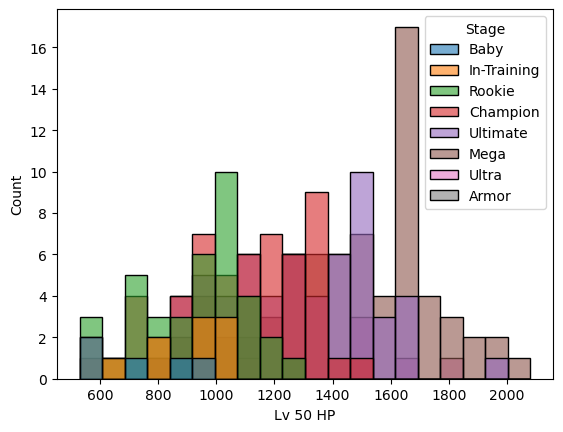

In [25]:
sns.histplot(
    data=digimon_df,
    x="Lv 50 HP",
    hue="Stage",
    bins=20,
    common_bins=True,
    alpha=0.6
)

plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:
The histogram suggests that Digimon in higher evolution stages generally have larger HP values than Digimon in lower stages. Rookie and Champion Digimon appear to have lower typical HP values, while Ultimate, Mega, and Ultra Digimon tend to be centered at higher HP values.

In [34]:
# Summary statistics

hp_stats = hp_df.groupby("Stage")["Lv 50 HP"].describe()

hp_stats

,count,mean,std,min,25%,50%,75%,max
Stage,,,,,,,,
Armor,3.0,1170.000000,60.827625,1130.0,1135.0,1140.0,1190.0,1240.0
Baby,5.0,728.000000,176.974574,540.0,590.0,690.0,870.0,950.0
Champion,54.0,1087.037037,224.168313,590.0,940.0,1130.0,1267.5,1480.0
In-Training,11.0,844.545455,187.742570,540.0,735.0,930.0,985.0,1040.0
Mega,74.0,1455.405405,287.765073,790.0,1252.5,1480.0,1680.0,2080.0
Rookie,38.0,920.526316,181.032286,530.0,790.0,960.0,1037.5,1230.0
Ultimate,58.0,1286.896552,255.103742,790.0,1090.0,1285.0,1480.0,1980.0
Ultra,6.0,1508.333333,239.951384,1080.0,1490.0,1510.0,1642.5,1780.0


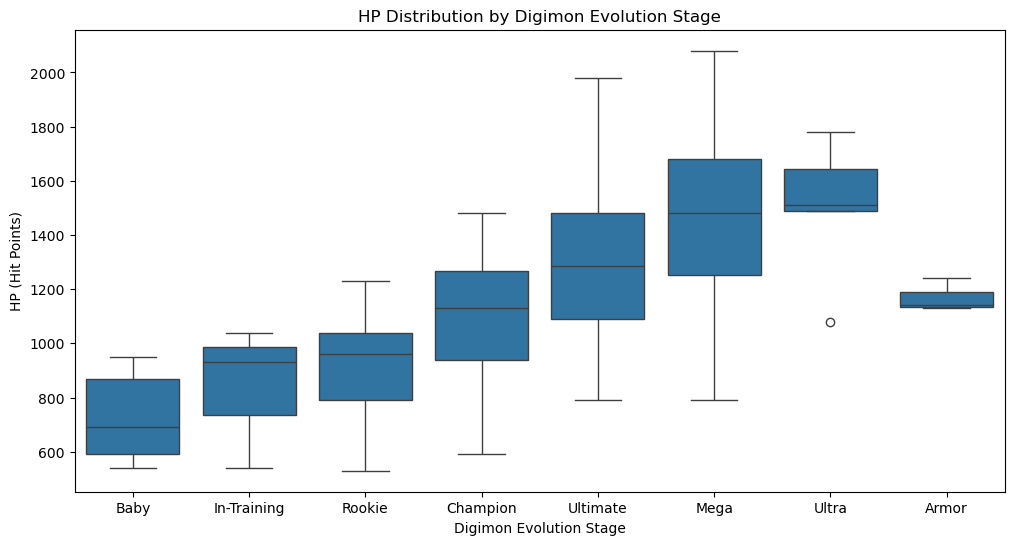

In [35]:
# Create and label the box-plot comparison

plt.figure(figsize=(12,6))

sns.boxplot(
    data=hp_df,
    x="Stage",
    y="Lv 50 HP"
)

plt.title("HP Distribution by Digimon Evolution Stage")
plt.xlabel("Digimon Evolution Stage")
plt.ylabel("HP (Hit Points)")

plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:
This chart agrees with my pridiction, but the Ultra form seems to be lower than expected in comparison to the others.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [36]:
hp_df.groupby("Stage")["Lv 50 HP"].agg(["min", "max", "count"])


,min,max,count
Stage,,,
Armor,1130,1240,3
Baby,540,950,5
Champion,590,1480,54
In-Training,540,1040,11
Mega,790,2080,74
Rookie,530,1230,38
Ultimate,790,1980,58
Ultra,1080,1780,6


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:
I would be suspicious if any Digimon had negative HP values because Hit Points represent health and cannot be negative. I would also be concerned if a Baby or In-Training Digimon had extremely large HP values compared to Mega or Ultra Digimon because this would contradict the expected progression of evolution stages. My check showed that all HP values were positive and fell within reasonable ranges for the game.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:My pridiction was spot on with Mega having a max of 2080 and baby max 950.The Ultra form has a lower max then the Ultimate and Mega.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:That Digimon evolution to mega form yeilds greater HP


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer:
How does the distribution of SP (Skill Points) differ among Digimon evolution stages (Stage) in the DigiDB dataset?

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:
Baby evolution stages would yeild more skill points then others

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:
I will use all Digimon records that contain valid values for Stage and Lv50 SP. Each observation represents one Digimon species from the DigiDB dataset, which contains game statistics and characteristics for Digimon from Digimon Story: Cyber Sleuth

In [37]:
sp_df = digimon_df[
    ["Stage", "Lv50 SP"]
].dropna()

sp_df.head()

,Stage,Lv50 SP
0,Baby,77
1,Baby,62
2,Baby,50
3,Baby,68
4,Baby,98


In [38]:
sp_df["Stage"].value_counts()


Stage
Mega           74
Ultimate       58
Champion       54
Rookie         38
In-Training    11
Ultra           6
Baby            5
Armor           3
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


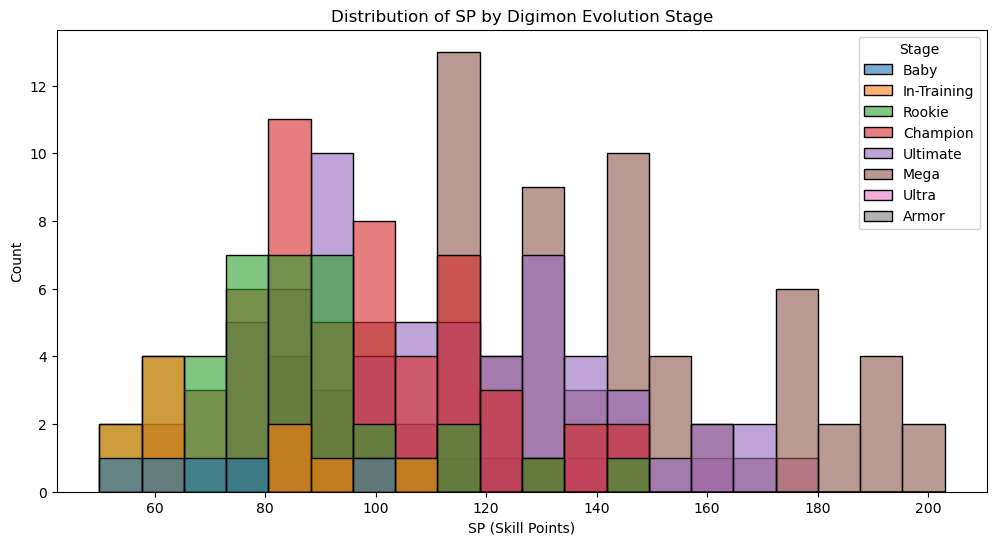

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(
    data=sp_df,
    x="Lv50 SP",
    hue="Stage",
    bins=20,
    common_bins=True,
    alpha=0.6
)

plt.title("Distribution of SP by Digimon Evolution Stage")
plt.xlabel("SP (Skill Points)")
plt.ylabel("Count")

plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:The histogram shows that SP values generally increase as Digimon progress through higher evolution stages. Baby and In-Training Digimon have the lowest typical SP values, mostly clustered between about 50 and 90 SP. Rookie and Champion Digimon are centered slightly higher, with many observations between roughly 75 and 120 SP. Ultimate Digimon tend to have higher typical SP values, often between 90 and 150 SP, while Mega and Ultra Digimon appear to have the highest SP values overall, with several observations extending beyond 150 SP.


In [40]:
sp_summary = (
    sp_df.groupby("Stage")["Lv50 SP"]
    .describe()
)

sp_summary

,count,mean,std,min,25%,50%,75%,max
Stage,,,,,,,,
Armor,3.0,110.333333,15.821926,93.0,103.50,114.0,119.00,124.0
Baby,5.0,71.000000,18.000000,50.0,62.00,68.0,77.00,98.0
Champion,54.0,97.703704,21.376790,59.0,84.00,96.0,113.00,148.0
In-Training,11.0,75.636364,19.428189,52.0,63.50,64.0,89.50,107.0
Mega,74.0,135.229730,31.214041,83.0,114.00,132.0,153.00,203.0
Rookie,38.0,85.184211,19.967345,51.0,71.75,86.0,93.00,148.0
Ultimate,58.0,112.241379,25.756151,74.0,90.00,109.0,133.00,168.0
Ultra,6.0,131.166667,33.162730,84.0,110.25,134.0,153.25,173.0


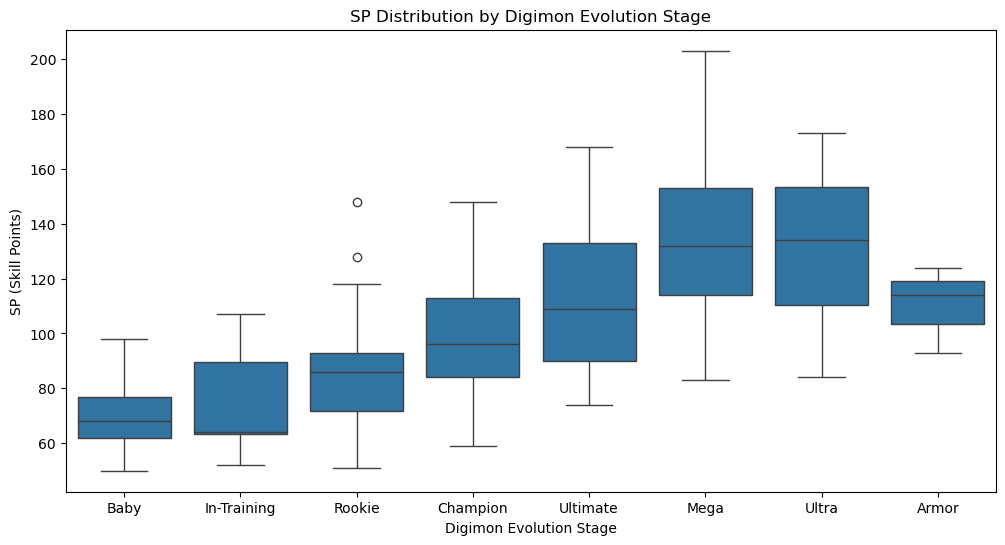

In [41]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=sp_df,
    x="Stage",
    y="Lv50 SP"
)

plt.title("SP Distribution by Digimon Evolution Stage")
plt.xlabel("Digimon Evolution Stage")
plt.ylabel("SP (Skill Points)")

plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:
The calculated summaries were consistent with my visual estimates from the histogram. Baby and In-Training Digimon had the lowest typical SP values, with median SP values around 65-70 SP. Rookie and Champion Digimon had somewhat higher centers, with medians near 85-100 SP. Ultimate Digimon had a median around 110 SP, while Mega and Ultra Digimon had the highest typical SP values, with medians around 130-135 SP. Armor Digimon were similar to Ultimate Digimon, with a median near 115 SP.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [42]:
sp_df.groupby("Stage")["Lv50 SP"].agg(["min", "max", "count"])

,min,max,count
Stage,,,
Armor,93,124,3
Baby,50,98,5
Champion,59,148,54
In-Training,52,107,11
Mega,83,203,74
Rookie,51,148,38
Ultimate,74,168,58
Ultra,84,173,6


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:If an evolution syage ha 0 or negitive sp


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:
The distribution of SP differed across Digimon evolution stages. The group sizes varied across stages, with Champion, Ultimate, and Mega Digimon having more observations than Baby, Ultra, and Armor Digimon. The center of the SP distribution generally increased as the evolution stage increased. Baby and In-Training Digimon had median SP values around 65–70 SP, while Ultimate Digimon had a median near 110 SP.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:
A reader should avoid concluding that simply evolving a Digimon causes its SP value to increase or that every Digimon in a higher evolution stage will have more SP than every Digimon in a lower stage.

## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer:
How does the distribution of Attack (Lv50 Atk) differ among Digimon evolution stages (Stage) in the DigiDB dataset?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:
I predict that Mega and Ultra Digimon will have higher Attack values than Baby, In-Training, Rookie, and Champion Digimon because higher evolution stages are generally designed to be stronger in battle. I expect the median Attack value to increase as evolution stage increases.

In [45]:
atk_df = digimon_df[
    ["Stage", "Lv50 Atk"]
].dropna()

atk_df.head()

,Stage,Lv50 Atk
0,Baby,79
1,Baby,76
2,Baby,97
3,Baby,77
4,Baby,54


In [46]:
atk_df["Stage"].value_counts()


Stage
Mega           74
Ultimate       58
Champion       54
Rookie         38
In-Training    11
Ultra           6
Baby            5
Armor           3
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


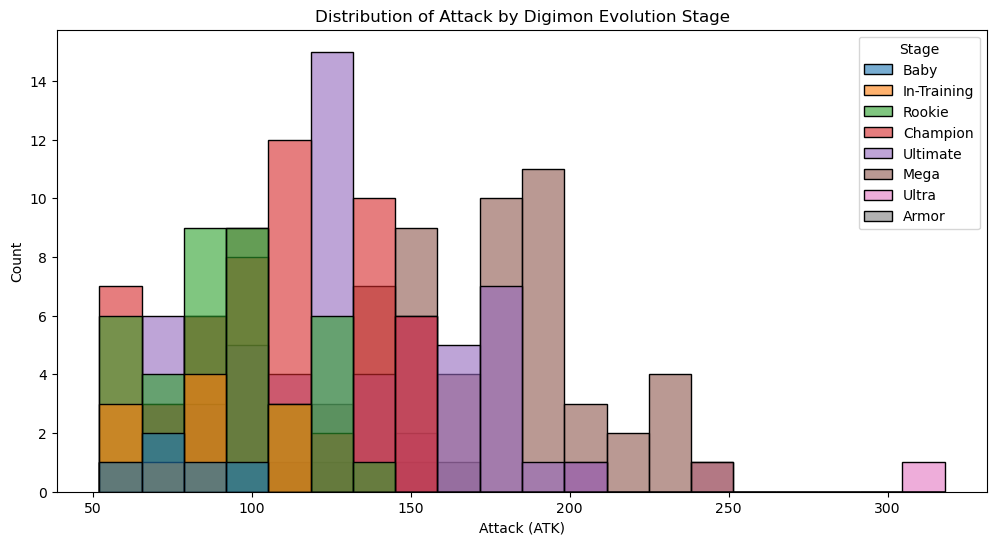

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.histplot(
    data=atk_df,
    x="Lv50 Atk",
    hue="Stage",
    bins=20,
    common_bins=True,
    alpha=0.6
)

plt.title("Distribution of Attack by Digimon Evolution Stage")
plt.xlabel("Attack (ATK)")
plt.ylabel("Count")

plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:
The histogram shows that Attack values generally increase as Digimon progress through higher evolution stages. Baby and In-Training Digimon have the lowest typical Attack values, mostly concentrated between about 50 and 110 ATK. Rookie Digimon are centered slightly higher, generally between 80 and 130 ATK, while Champion Digimon are concentrated around 100 to 160 ATK. Ultimate Digimon tend to have Attack values between approximately 110 and 200 ATK. Mega Digimon have the highest concentration of values, typically between 170 and 220 ATK, while Ultra Digimon are also centered at high Attack values but appear to have fewer observations. Armor Digimon fall in the middle of the distribution, overlapping with Champion and Ultimate Digimon.

In [48]:
atk_summary = (
    atk_df.groupby("Stage")["Lv50 Atk"]
    .describe()
)

atk_summary

,count,mean,std,min,25%,50%,75%,max
Stage,,,,,,,,
Armor,3.0,148.333333,25.890796,119.0,138.50,158.0,163.00,168.0
Baby,5.0,76.600000,15.274161,54.0,76.00,77.0,79.00,97.0
Champion,54.0,108.166667,29.241190,59.0,85.25,108.0,136.75,155.0
In-Training,11.0,81.454545,20.329110,54.0,68.00,82.0,96.00,109.0
Mega,74.0,152.621622,46.718540,64.0,106.50,156.0,188.00,243.0
Rookie,38.0,91.789474,24.200913,52.0,73.75,90.5,112.00,133.0
Ultimate,58.0,129.120690,35.811435,64.0,105.75,124.0,158.00,203.0
Ultra,6.0,194.833333,80.849036,89.0,153.25,181.0,237.25,318.0


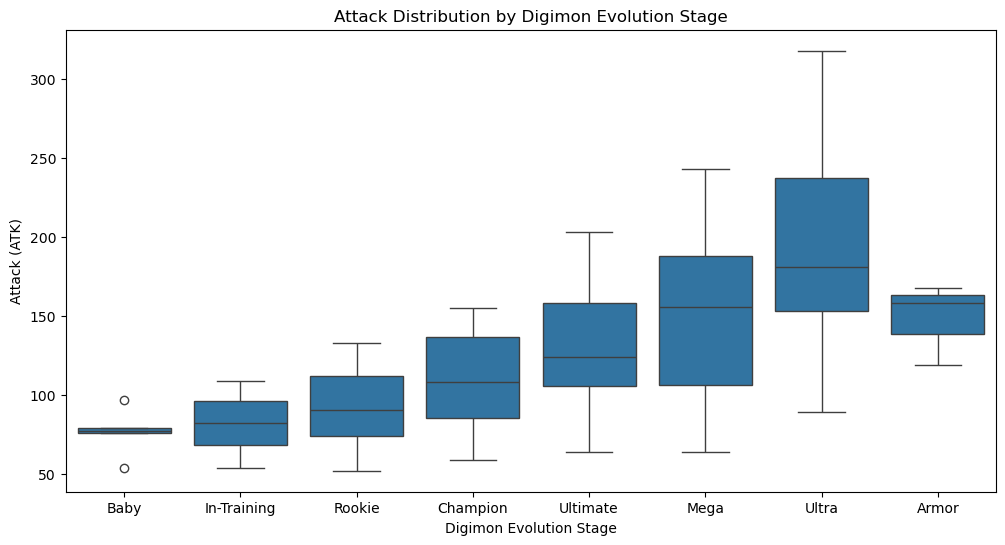

In [49]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=atk_df,
    x="Stage",
    y="Lv50 Atk"
)

plt.title("Attack Distribution by Digimon Evolution Stage")
plt.xlabel("Digimon Evolution Stage")
plt.ylabel("Attack (ATK)")

plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:
The calculated summaries were consistent with my visual estimates from the histogram. Baby and In-Training Digimon had the lowest typical Attack values, with median Attack values around 75-85 ATK. Rookie and Champion Digimon had moderately higher centers, with medians near 90-110 ATK. Ultimate Digimon had a median Attack value around 125 ATK, while Mega and Ultra Digimon had the highest median Attack values, approximately 155-180 ATK. Armor Digimon were similar to Mega Digimon, with a median near 160 ATK.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [50]:
atk_df.groupby("Stage")["Lv50 Atk"].agg(
    ["min", "max", "count"]
)

,min,max,count
Stage,,,
Armor,119,168,3
Baby,54,97,5
Champion,59,155,54
In-Training,54,109,11
Mega,64,243,74
Rookie,52,133,38
Ultimate,64,203,58
Ultra,89,318,6


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:
I would be suspicious if any Digimon had a negative Attack value because Attack is a combat statistic and should always be positive. I would also be suspicious if Baby or In-Training Digimon consistently had higher Attack values than Mega or Ultra Digimon, since higher evolution stages are generally expected to have stronger battle statistics.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:
The distribution of Attack values differed across Digimon evolution stages. The groups varied in size, but each stage contained enough observations to compare the distributions. The median Attack value generally increased as Digimon evolved. Baby and In-Training Digimon had median Attack values around 75-85 ATK, Rookie Digimon had a median near 90 ATK, Champion Digimon had a median around 105 ATK, and Ultimate Digimon had a median near 125 ATK. Mega and Ultra Digimon had the highest centers, with median Attack values of approximately 155 ATK and 180 ATK, respectively. Armor Digimon had a median near 160 ATK, similar to Mega Digimon.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:
A reader should avoid concluding that simply evolving a Digimon guarantees a higher Attack value or that every Digimon in a higher evolution stage is stronger than every Digimon in a lower stage. Although Mega and Ultra Digimon generally had higher Attack values, there was still substantial overlap between stages. Some Champion or Ultimate Digimon had Attack values comparable to those of certain Mega Digimon.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:
N/A

## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
